In [8]:
# Cell 0: required headers
YOUR_NAME = "Nitya Dhagat (200483337)"   # <-- edit
import torch, transformers
print("Name:", YOUR_NAME)
print("torch:", torch.__version__)
print("transformers:", transformers.__version__)

Name: Nitya Dhagat (200483337)
torch: 2.15.0+cpu
transformers: 5.22.2


# PA2 Part 3: Dissecting a Pretrained LLM (Pythia-160m-deduped)

Setup: upload `test_LM_obama.txt` next to this notebook (or edit `OBAMA_PATH`). Checkpoints are downloaded from the Hugging Face hub (about 650 MB each).

In [9]:
import gc, math, numpy as np
import torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from transformers import AutoTokenizer, GPTNeoXForCausalLM

NAME = "EleutherAI/pythia-160m-deduped"
OBAMA_PATH = "./speechesdataset/test_LM_obama.txt"      # <-- edit if needed
device = "cuda" if torch.cuda.is_available() else "cpu"
tok = AutoTokenizer.from_pretrained(NAME)

def load(step):
    m = GPTNeoXForCausalLM.from_pretrained(NAME, revision=f"step{step}", torch_dtype=torch.float32)
    return m.to(device).eval()

def free(*objs):
    for o in objs: del o
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

# ---- data: tokenize the whole Obama test file, cut into fixed-length chunks ----
text = open(OBAMA_PATH, encoding="utf-8").read()
all_ids = tok(text, return_tensors="pt").input_ids[0]
CHUNK = 256
n_chunks = len(all_ids) // CHUNK
chunks = all_ids[: n_chunks * CHUNK].view(n_chunks, CHUNK)
print(f"{len(all_ids)} tokens -> {n_chunks} chunks of {CHUNK} (remainder {len(all_ids) - n_chunks*CHUNK} dropped)")

6017 tokens -> 23 chunks of 256 (remainder 129 dropped)


## 3.1 Reading Pythia

**1. Why checkpoints? (2 pts)**

*YOUR ANSWER HERE (a few sentences, cite sections of Biderman et al.)*

**2. Data (2 pts)**

*YOUR ANSWER HERE (one finding for deduped vs. non-deduped, with section)*

## 3.2 The Logit Lens

### Readout helpers (and the "is LN already applied to the last hidden state?" check)

In [10]:
def get_readout(model):
    ln_f = model.gpt_neox.final_layer_norm
    W_U = model.get_output_embeddings()
    return ln_f, W_U

@torch.no_grad()
def check_last_hidden_has_ln(model, ids):
    """Compare the readout of hidden_states[-1] with out.logits, with and without LN_f."""
    ln_f, W_U = get_readout(model)
    out = model(ids, output_hidden_states=True)
    h = out.hidden_states[-1]
    no_ln = (W_U(h) - out.logits).abs().max().item()
    with_ln = (W_U(ln_f(h)) - out.logits).abs().max().item()
    print(f"max |W_U(h_L) - logits|        = {no_ln:.2e}")
    print(f"max |W_U(LN_f(h_L)) - logits|  = {with_ln:.2e}")
    return no_ln < with_ln   # True -> last entry already has LN applied

@torch.no_grad()
def lens_logits(model, hidden_states, last_has_ln):
    """Logit-lens logits for every layer: list of L+1 tensors (B, T, V)."""
    ln_f, W_U = get_readout(model)
    L = len(hidden_states) - 1
    outs = []
    for l, h in enumerate(hidden_states):
        if l == L and last_has_ln:
            outs.append(W_U(h))
        else:
            outs.append(W_U(ln_f(h)))
    return outs

model = load(143000)
LAST_HAS_LN = check_last_hidden_has_ln(model, chunks[:1].to(device))
print("last hidden state already has LN_f applied:", LAST_HAS_LN)

c:\Users\NityaDhagat\anaconda3\envs\pa2\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\NityaDhagat\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 148/148 [00:01<00:00, 135.45it/s]


max |W_U(h_L) - logits|        = 0.00e+00
max |W_U(LN_f(h_L)) - logits|  = 3.81e+01
last hidden state already has LN_f applied: True


### 3.2.1 Watch a prediction form

sentence 1 tokens: 11 | sentence 2 tokens: 18


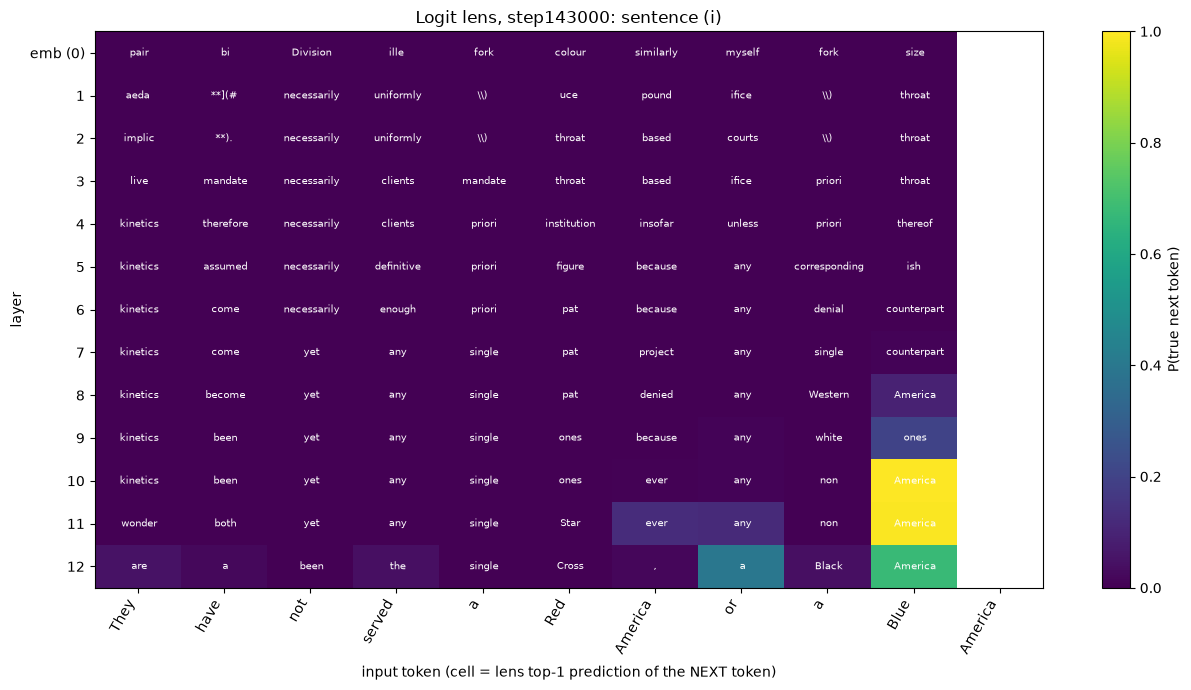

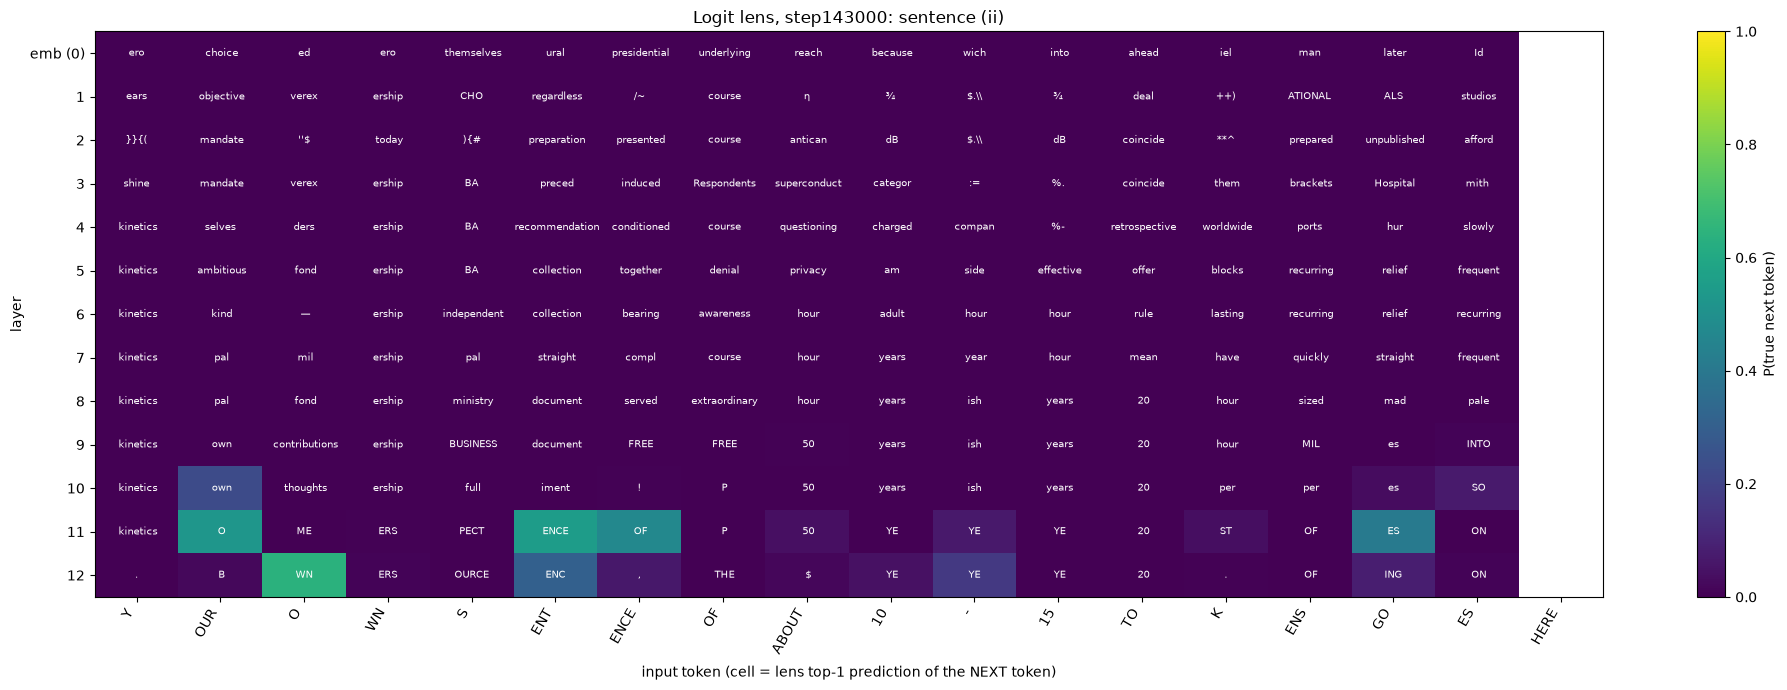

In [11]:
@torch.no_grad()
def plot_lens_grid(model, sentence, title):
    ids = tok(sentence, return_tensors="pt").input_ids.to(device)
    out = model(ids, output_hidden_states=True)
    logits = lens_logits(model, out.hidden_states, LAST_HAS_LN)   # 13 x (1, T, V)
    T = ids.shape[1]
    nxt = ids[0, 1:]                                              # true next tokens, length T-1
    probs = torch.full((len(logits), T), float("nan"))
    tops = []
    for l, lg in enumerate(logits):
        p = lg[0].softmax(-1)
        tops.append([tok.decode(i) for i in p.argmax(-1).tolist()])
        probs[l, : T - 1] = p[torch.arange(T - 1), nxt].cpu()
    fig, ax = plt.subplots(figsize=(1.0 * T + 2, 7))
    im = ax.imshow(probs.numpy(), cmap="viridis", vmin=0, vmax=1, aspect="auto", origin="upper")
    for l in range(len(logits)):
        for t in range(T):
            ax.text(t, l, repr(tops[l][t])[1:-1], ha="center", va="center", fontsize=7, color="w")
    toks = [tok.decode(i) for i in ids[0]]
    ax.set_xticks(range(T)); ax.set_xticklabels([repr(t)[1:-1] for t in toks], rotation=60, ha="right")
    ax.set_yticks(range(len(logits))); ax.set_yticklabels(["emb (0)"] + [str(i) for i in range(1, len(logits))])
    ax.set_xlabel("input token (cell = lens top-1 prediction of the NEXT token)")
    ax.set_ylabel("layer"); ax.set_title(title)
    fig.colorbar(im, ax=ax, label="P(true next token)")
    plt.tight_layout(); plt.show()

sent1 = "They have not served a Red America or a Blue America"
assert sent1 in text, "sentence (i) must come from test_LM_obama.txt"
sent2 = "YOUR OWN SENTENCE OF ABOUT 10-15 TOKENS GOES HERE"   # <-- edit
print("sentence 1 tokens:", len(tok(sent1).input_ids), "| sentence 2 tokens:", len(tok(sent2).input_ids))
plot_lens_grid(model, sent1, "Logit lens, step143000: sentence (i)")
plot_lens_grid(model, sent2, "Logit lens, step143000: sentence (ii)")

In [12]:
@torch.no_grad()
def lens_accuracy_by_layer(model, batch_size=8):
    """Top-1 accuracy of the lens for the true next token, over all chunks, per layer 0..12."""
    correct = None; total = 0
    for i in range(0, len(chunks), batch_size):
        ids = chunks[i:i + batch_size].to(device)
        out = model(ids, output_hidden_states=True)
        lgs = lens_logits(model, out.hidden_states, LAST_HAS_LN)
        if correct is None: correct = np.zeros(len(lgs))
        tgt = ids[:, 1:]
        for l, lg in enumerate(lgs):
            correct[l] += (lg[:, :-1].argmax(-1) == tgt).sum().item()
        total += tgt.numel()
    return correct / total

acc_final = lens_accuracy_by_layer(model)
plt.figure(figsize=(6, 4)); plt.plot(range(13), acc_final, "o-")
plt.xlabel("layer"); plt.ylabel("lens top-1 accuracy"); plt.title("step143000: accuracy by layer")
plt.grid(alpha=.3); plt.show()
for l in (0, 6, 12):
    print(f"step143000, layer {l:2d}: top-1 accuracy = {acc_final[l]:.4f}")

RuntimeError: [enforce fail at alloc_cpu.cpp:117] data. DefaultCPUAllocator: not enough memory: you tried to allocate 412090368 bytes.

**Notes on 3.2.1** *(optional: describe what you see in the two grids; it must match your figures)*

*YOUR ANSWER HERE*

### 3.2.2 Across training

In [ ]:
STEPS_LENS = [512, 1000, 8000, 143000]
curves = {143000: acc_final}
free(model)
for s in STEPS_LENS:
    if s in curves: continue
    m = load(s)
    curves[s] = lens_accuracy_by_layer(m)
    free(m)

plt.figure(figsize=(7, 4.5))
for s in STEPS_LENS:
    plt.plot(range(13), curves[s], "o-", label=f"step{s}")
plt.xlabel("layer"); plt.ylabel("lens top-1 accuracy"); plt.legend(); plt.grid(alpha=.3)
plt.title("Logit-lens accuracy by layer across training"); plt.show()
for s in STEPS_LENS:
    print(f"step{s:>6}: " + "  ".join(f"L{l}={curves[s][l]:.4f}" for l in (0, 6, 12)))

**Answer (3.2.2):** do the middle layers become more or less readable as training goes on? What does it suggest about whether the middle hidden states are in the same "language" as the output layer?

*YOUR ANSWER HERE: back it with numbers from the plot / printout above.*

## 3.3 Transplanting Layers Across Time

In [ ]:
@torch.no_grad()
def test_loss(model, batch_size=8):
    tot, n = 0.0, 0
    for i in range(0, len(chunks), batch_size):
        ids = chunks[i:i + batch_size].to(device)
        logits = model(ids).logits[:, :-1]
        l = F.cross_entropy(logits.reshape(-1, logits.size(-1)), ids[:, 1:].reshape(-1), reduction="sum")
        tot += l.item(); n += ids[:, 1:].numel()
    return tot / n

N_LAYERS = 12
COMPONENTS = ["gpt_neox.embed_in"] + [f"gpt_neox.layers.{i}" for i in range(N_LAYERS)] + ["embed_out"]
ROW_LABELS = ["embedding"] + [f"layer {i}" for i in range(N_LAYERS)] + ["unembedding"]
DONORS = [0, 1000, 8000, 32000]

final = load(143000)
base_loss = test_loss(final)
print(f"Intact step143000 test loss: {base_loss:.4f}")
orig_state = {c: {k: v.clone() for k, v in final.get_submodule(c).state_dict().items()} for c in COMPONENTS}

delta = np.zeros((len(COMPONENTS), len(DONORS)))
for j, d in enumerate(DONORS):
    donor = load(d)
    for i, c in enumerate(COMPONENTS):
        final.get_submodule(c).load_state_dict(donor.get_submodule(c).state_dict())   # transplant
        delta[i, j] = test_loss(final) - base_loss
        final.get_submodule(c).load_state_dict(orig_state[c])                         # restore
    free(donor)
assert abs(test_loss(final) - base_loss) < 1e-6, "model was not restored correctly"
print("restored OK")

In [ ]:
VMIN = 1e-3
clipped = np.clip(delta, VMIN, None)
fig, ax = plt.subplots(figsize=(7, 8))
im = ax.imshow(clipped, cmap="magma_r", norm=LogNorm(vmin=VMIN, vmax=clipped.max()), aspect="auto")
ax.set_xticks(range(len(DONORS))); ax.set_xticklabels([f"step{d}" for d in DONORS])
ax.set_yticks(range(len(COMPONENTS))); ax.set_yticklabels(ROW_LABELS)
for i in range(len(COMPONENTS)):
    for j in range(len(DONORS)):
        v = clipped[i, j]
        dark = LogNorm(vmin=VMIN, vmax=clipped.max())(v) > 0.5
        ax.text(j, i, f"{delta[i, j]:.3f}", ha="center", va="center", fontsize=8, color="w" if dark else "k")
ax.set_xlabel("donor checkpoint"); ax.set_ylabel("component replaced in step143000")
ax.set_title(f"Change in test loss (base {base_loss:.3f}); colour clipped at {VMIN}")
fig.colorbar(im, ax=ax, label="delta loss (log scale)")
plt.tight_layout(); plt.show()

import pandas as pd
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
print(pd.DataFrame(delta, index=ROW_LABELS, columns=[f"step{d}" for d in DONORS]))

**Answer (3.3):** which components can the model lose (replaced by random step0 weights) with little damage, and which are irreplaceable? Does a later donor always hurt less than an earlier one? Explain, especially any component where a later donor hurts more.

*YOUR ANSWER HERE: every claim must cite a number from the heatmap/table above (or an extra plot you add below).*